# Build a modelling script from first principles

This tutorial assembles every object needed for a reproducible strong-lens modelling script. It uses a small simulated observation so every cell can be executed, but the construction is the same for FITS data: load arrays, construct an `ImagingObservation`, define image and source grids, declare fixed and free lens parameters, optimize the source-marginalized posterior, and sample it.

The central dependency chain is:

`arrays -> ImagingObservation + CartesianGrid -> SourceGrid + PixelizedLensModel -> fit -> sample -> saved results`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from akira import (
    CartesianGrid, EllipticalPowerLaw, ExternalShear, FreeParameter,
    LensPlane, PixelizedLensModel, ProfileModel, SourceGrid, UniformPrior,
    fit_pixelized_model, gaussian_psf, lensing_operator,
    sample_pixelized_model, simulate_imaging,
)

## 1. Coordinate and array contract

All image arrays have shape `(ny, nx)`. Coordinates are public `(x, y)` pairs in arcseconds. Positive array columns increase `x`, positive rows increase `y`, and profile angles are radians anticlockwise from positive `x`. A FITS workflow should derive `pixel_scale` and any crop-relative lens centre from the WCS before discarding the header.

The `CartesianGrid` describes where image pixels and optional subpixels lie. It must have the same shape as the observation.

In [2]:
image_grid = CartesianGrid(shape=(20, 20), pixel_scale=0.10, supersampling=1)
source_grid = SourceGrid(shape=(6, 6), pixel_scale=0.06, centre=(0.03, -0.02))

print('image shape:', image_grid.shape)
print('image field of view [arcsec]:', np.array(image_grid.shape[::-1]) * image_grid.pixel_scale)
print('source pixels:', source_grid.size)

image shape: (20, 20)
image field of view [arcsec]: [2. 2.]
source pixels: 36


## 2. Construct an observation

An `ImagingObservation` contains four measured ingredients: data, per-pixel noise standard deviations, a normalized odd-sized PSF kernel, and a Boolean mask where `True` means excluded. Here we simulate them from a known source and lens. In a real script, replace this section with FITS loading and validate that all arrays are finite and shape-compatible.

In [3]:
true_lens = LensPlane((
    EllipticalPowerLaw(
        einstein_radius=0.68, slope=2.04, centre=(0.01, -0.02),
        q=0.80, phi=0.28,
    ),
    ExternalShear(strength=0.025, phi=0.70),
))

source_coordinates = np.asarray(source_grid.coordinates())
sx, sy = source_coordinates[..., 0], source_coordinates[..., 1]
true_source = (
    np.exp(-0.5 * ((sx - 0.05)**2 / 0.065**2 + (sy + 0.02)**2 / 0.045**2))
    + 0.35 * np.exp(-0.5 * ((sx + 0.07)**2 / 0.035**2 + (sy - 0.06)**2 / 0.040**2))
)

unconvolved = (
    lensing_operator(image_grid, source_grid, true_lens) @ true_source.reshape(-1)
).reshape(image_grid.shape)
psf = gaussian_psf(sigma_pixels=0.65, size=5)
observation = simulate_imaging(
    unconvolved, psf, noise_sigma=0.012,
    pixel_scale=image_grid.pixel_scale, seed=14,
)

assert observation.data.shape == image_grid.shape
assert observation.noise_map.shape == image_grid.shape
assert observation.mask.shape == image_grid.shape
assert np.isclose(np.asarray(observation.psf.kernel).sum(), 1.0)

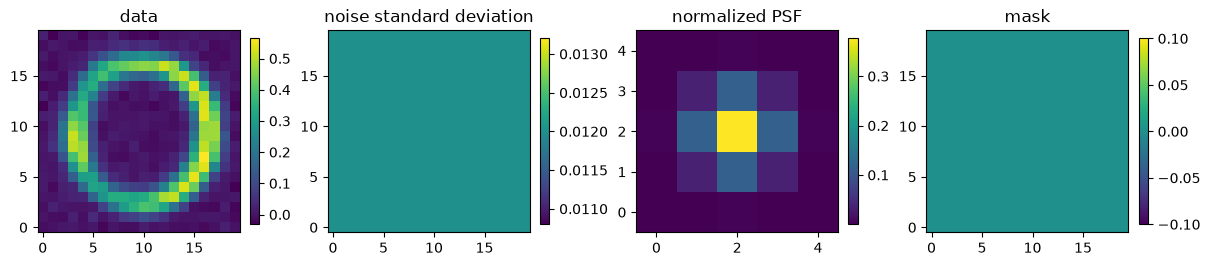

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for axis, values, title in zip(
    axes,
    (observation.data, observation.noise_map, observation.psf.kernel, observation.mask),
    ('data', 'noise standard deviation', 'normalized PSF', 'mask'),
):
    shown = axis.imshow(np.asarray(values), origin='lower')
    axis.set_title(title)
    fig.colorbar(shown, ax=axis, fraction=0.046)
plt.show()

## 3. Declare the nonlinear model and priors

A `ProfileModel` is a declarative profile template. Plain numbers are fixed; `FreeParameter` values enter the inference vector. Each free value needs an initial point and a normalized prior. The order of `model.parameter_names` is the authoritative vector order.

The source pixels are not declared as nonlinear parameters. They are solved linearly and marginalized analytically for every proposed lens.

In [5]:
model = PixelizedLensModel(
    lens=(
        ProfileModel(
            EllipticalPowerLaw,
            einstein_radius=FreeParameter(0.64, UniformPrior(0.55, 0.80)),
            slope=FreeParameter(1.95, UniformPrior(1.75, 2.30)),
            centre=(0.01, -0.02),
            q=0.80,
            phi=0.28,
        ),
        ProfileModel(ExternalShear, strength=0.025, phi=0.70),
    ),
    source_grid=source_grid,
    regularization_kind='gradient',
    regularization_strength=25.0,
)

print('parameter names:')
for name, value in zip(model.parameter_names, np.asarray(model.initial_vector)):
    print(f'  {name}: {value:.4f}')
print('initial log prior:', float(model.log_prior(model.initial_vector)))

parameter names:
  lens.0.EllipticalPowerLaw.einstein_radius: 0.6400
  lens.0.EllipticalPowerLaw.slope: 1.9500


initial log prior: 1.9841313618755114


## 4. Optimize the source-marginalized posterior

`fit_pixelized_model` rebuilds the lensing-plus-PSF operator for each nonlinear proposal, solves the regularized source, and optimizes the Gaussian source evidence plus the nonlinear parameter priors. Set `optimize_regularization_strength=True` to optimize `log(lambda)` jointly.

In [6]:
fit = fit_pixelized_model(
    model, observation, image_grid,
    objective='evidence',
    optimize_regularization_strength=True,
    log_strength_bounds=(np.log(0.1), np.log(1.0e4)),
)

print('success:', fit.success, '-', fit.message)
for name, value in fit.parameters.items():
    print(f'{name}: {value:.6g}')
print('chi squared:', fit.reconstruction.chi_squared)
print('log source evidence:', fit.log_source_evidence)

success: True - CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lens.0.EllipticalPowerLaw.einstein_radius: 0.680151
lens.0.EllipticalPowerLaw.slope: 2.03753
regularization.log_strength: 2.3944
regularization.strength: 10.9616
chi squared: 360.64627488924145
log source evidence: 1138.7135067574588


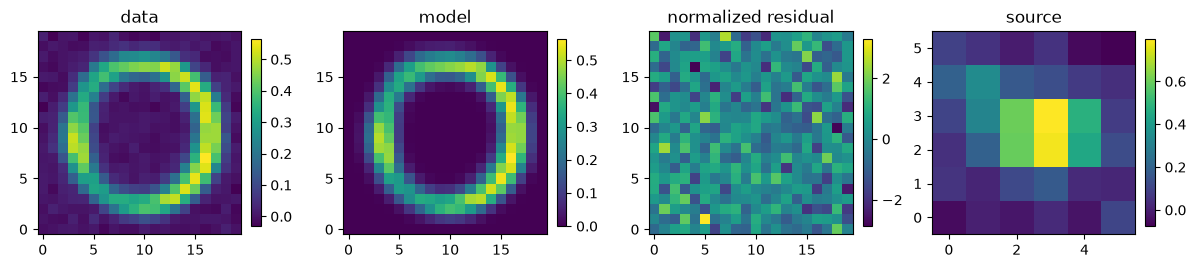

In [7]:
reconstruction = fit.reconstruction
residual = np.asarray(reconstruction.residuals).copy()
residual[np.asarray(observation.mask)] = np.nan

fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for axis, values, title in zip(
    axes,
    (observation.data, reconstruction.model_image, residual, reconstruction.source),
    ('data', 'model', 'normalized residual', 'source'),
):
    shown = axis.imshow(np.asarray(values), origin='lower')
    axis.set_title(title)
    fig.colorbar(shown, ax=axis, fraction=0.046)
plt.show()

## 5. Sample the posterior

An optimizer gives one point and a local Hessian approximation. The ensemble sampler reveals skewness, degeneracies, and prior truncation. It evaluates the same source-marginalized posterior, so only nonlinear lens parameters and optionally `log(lambda)` enter the chain.

This demonstration is deliberately short. Scientific chains should use more walkers and steps, discard an adequate burn-in, and be checked with trace plots, acceptance fractions, autocorrelation estimates, and independent runs.

In [8]:
sampling = sample_pixelized_model(
    model, observation, image_grid,
    initial_vector=np.asarray(fit.parameter_vector),
    sample_regularization_strength=True,
    log_strength_bounds=(np.log(0.1), np.log(1.0e4)),
    n_walkers=8, n_steps=30, burn_in=10, thin=2, seed=21,
)

samples = sampling.samples
print('saved sample matrix:', samples.shape)
print('mean acceptance fraction:', sampling.acceptance_fraction.mean())
for index, name in enumerate(sampling.parameter_names):
    p16, p50, p84 = np.percentile(samples[:, index], [16, 50, 84])
    print(f'{name}: {p50:.5g} -{p50-p16:.2g} +{p84-p50:.2g}')

saved sample matrix: (80, 3)
mean acceptance fraction: 0.5541666666666667
lens.0.EllipticalPowerLaw.einstein_radius: 0.67992 -0.00062 +0.00057
lens.0.EllipticalPowerLaw.slope: 2.0431 -0.018 +0.0064
regularization.log_strength: 2.4205 -0.11 +0.14


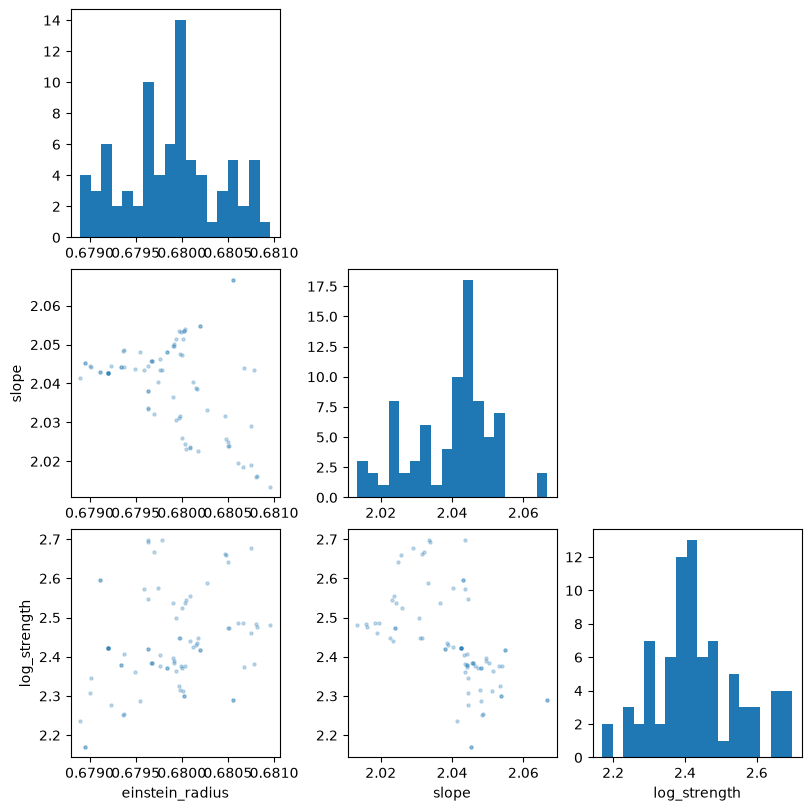

In [9]:
dimensions = samples.shape[1]
fig, axes = plt.subplots(dimensions, dimensions, figsize=(8, 8), constrained_layout=True)
labels = [name.split('.')[-1] for name in sampling.parameter_names]
for row in range(dimensions):
    for column in range(dimensions):
        axis = axes[row, column]
        if row < column:
            axis.set_visible(False)
        elif row == column:
            axis.hist(samples[:, column], bins=18)
        else:
            axis.scatter(samples[:, column], samples[:, row], s=5, alpha=0.25)
        if row == dimensions - 1 and axis.get_visible():
            axis.set_xlabel(labels[column])
        if column == 0 and row > 0:
            axis.set_ylabel(labels[row])
plt.show()

## 6. Turning the notebook into a modelling script

A production script should separate construction from execution:

1. `load_observation(config)` loads and validates data, noise, PSF, and mask.
2. `build_grids(config, data_shape)` constructs immutable image and source grids.
3. `build_model(config, source_grid)` converts fixed values and prior specifications into `ProfileModel` objects.
4. `fit_pixelized_model(...)` finds a stable starting point. A staged fit is safer when many lens parameters are free.
5. `sample_pixelized_model(...)` starts walkers near the fitted point and maps the posterior.
6. Save the exact configuration, parameter names, chains, log probabilities, acceptance fractions, reconstructed source, model image, residuals, and software version.

Before interpreting a result, verify: WCS/crop-relative centres; angle and ellipticity conventions; PSF centring and edge decay; mask semantics; realistic noise covariance; source-grid coverage; residual structure; posterior convergence; and whether any posterior is truncated by its prior.

For FITS-driven work, `examples/fit_real_data.py` is the corresponding configuration-based script. This notebook explains the objects that script constructs for you.